# 01 · Data exploration

What is actually on disk, measured rather than claimed. Everything here reads `results/metrics/dataset_summary.json` and the processed image index written by `scripts/run_preprocessing.py`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import config, data_loader, preprocess
from src.utils import setup_matplotlib
plt = setup_matplotlib()
%matplotlib inline
MET, FIG = config.PATHS.metrics, config.PATHS.figures
def show(name):
    from IPython.display import Image, display
    p = FIG / name
    display(Image(filename=str(p))) if p.exists() else print(f"{name} not generated yet")

## Headline numbers and claims vs measurement

In [2]:
s = json.loads((MET / 'dataset_summary.json').read_text(encoding='utf-8'))
print(f"{s['total_images']:,} images, {s['num_classes']} classes")
print('images per class:', s['images_per_class'])
for d in s['claims_vs_measured']['differences']: print(' -', d)

575,912 images, 57 classes
images per class: {'min': 10098, 'max': 10110, 'mean': 10103.72, 'median': 10100.0, 'std': 4.85, 'imbalance_ratio_max_over_min': 1.001}
 - digit: uploader claims 101,100 images, found 101,095 (-5).
 - consonant: uploader claims 353,500 images, found 353,497 (-3).
 - Uploader claims 575,920 images; found 575,912 (-8).
 - Measured: 12 vowel + 35 consonant = 47 letter classes, plus 10 digit classes = 57 total (excluding any 'other'). Papers report 46; the uploader's own breakdown (12 + 35 = 47 letters + 10 digits) implies 57. Neither 46 nor 47 is guaranteed to be the same character inventory as this dataset.


In [3]:
pd.DataFrame({k: {kk: v[kk] for kk in ('classes', 'images')} for k, v in s['categories'].items()}).T

,classes,images
consonant,35,353497
digit,10,101095
vowel,12,121320


## Class balance
The dataset is almost perfectly balanced (max/min ≈ 1.001), so plain accuracy is a fair headline metric. Macro-F1 is reported anyway.

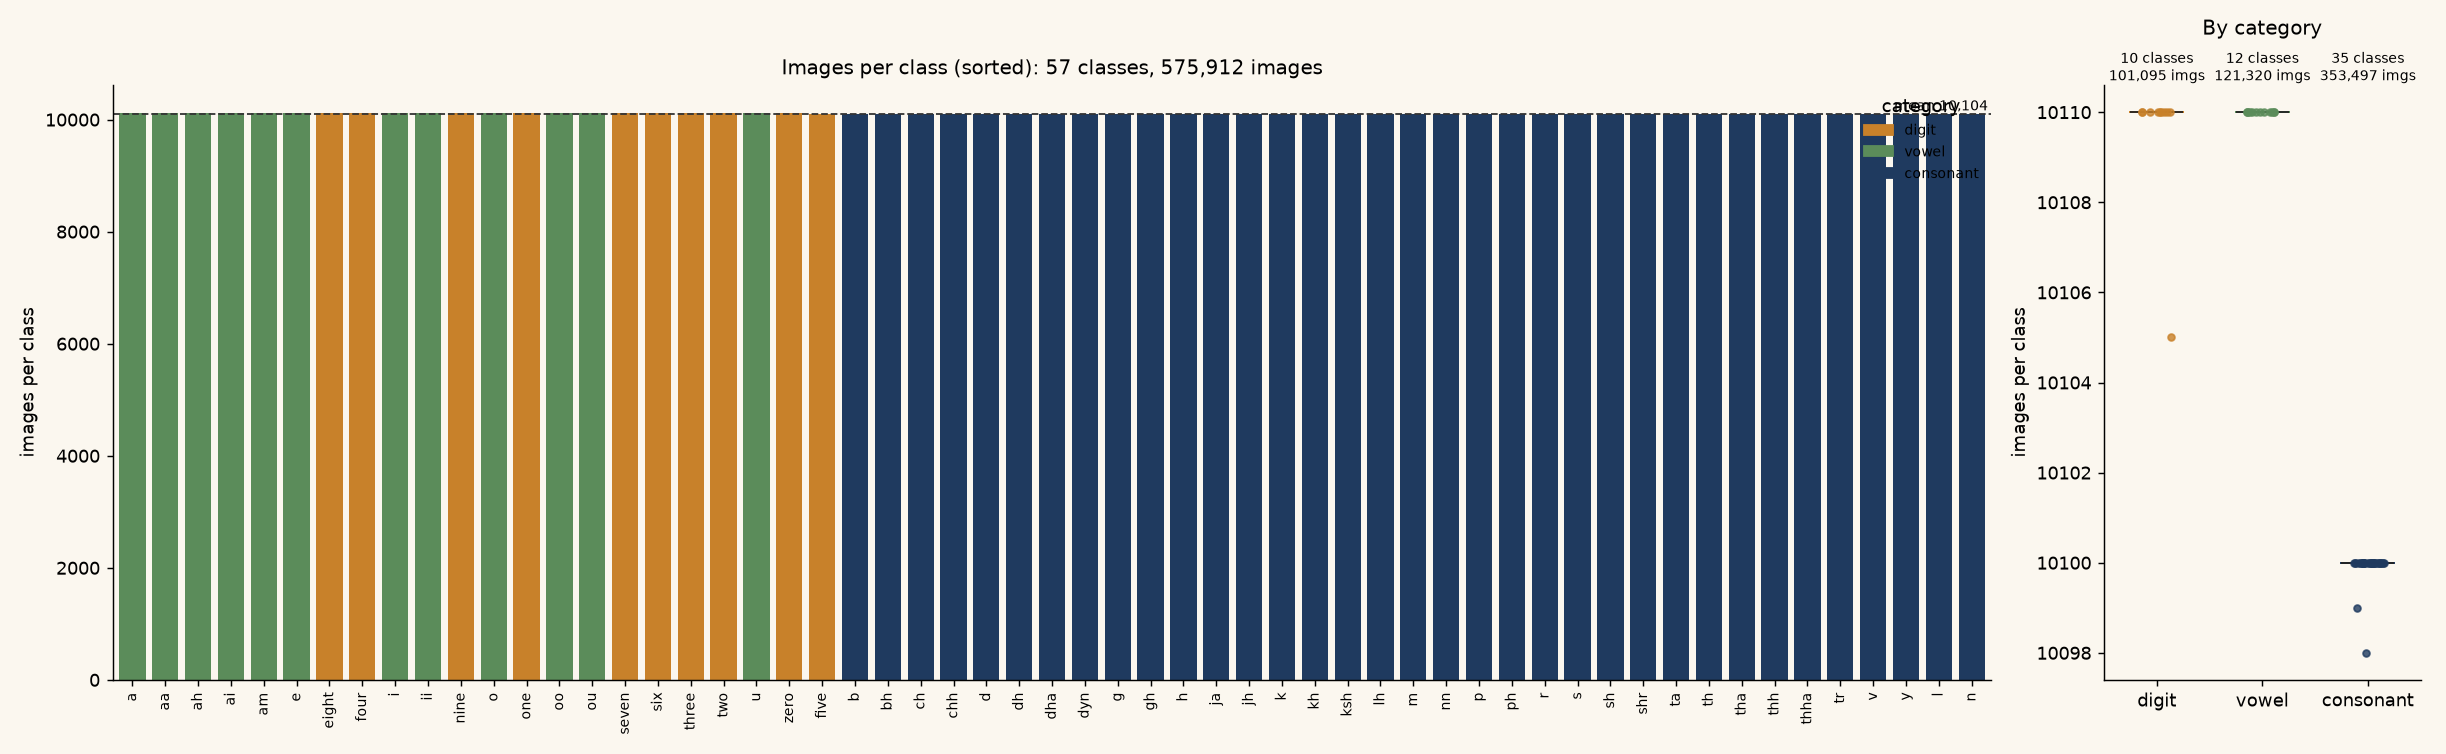

In [4]:
show('class_distribution.png')

## What the classes look like
Three training examples per class. Use this to verify the Devanagari mapping in `src/labels.json`: the ten dental/retroflex classes are marked `?`.

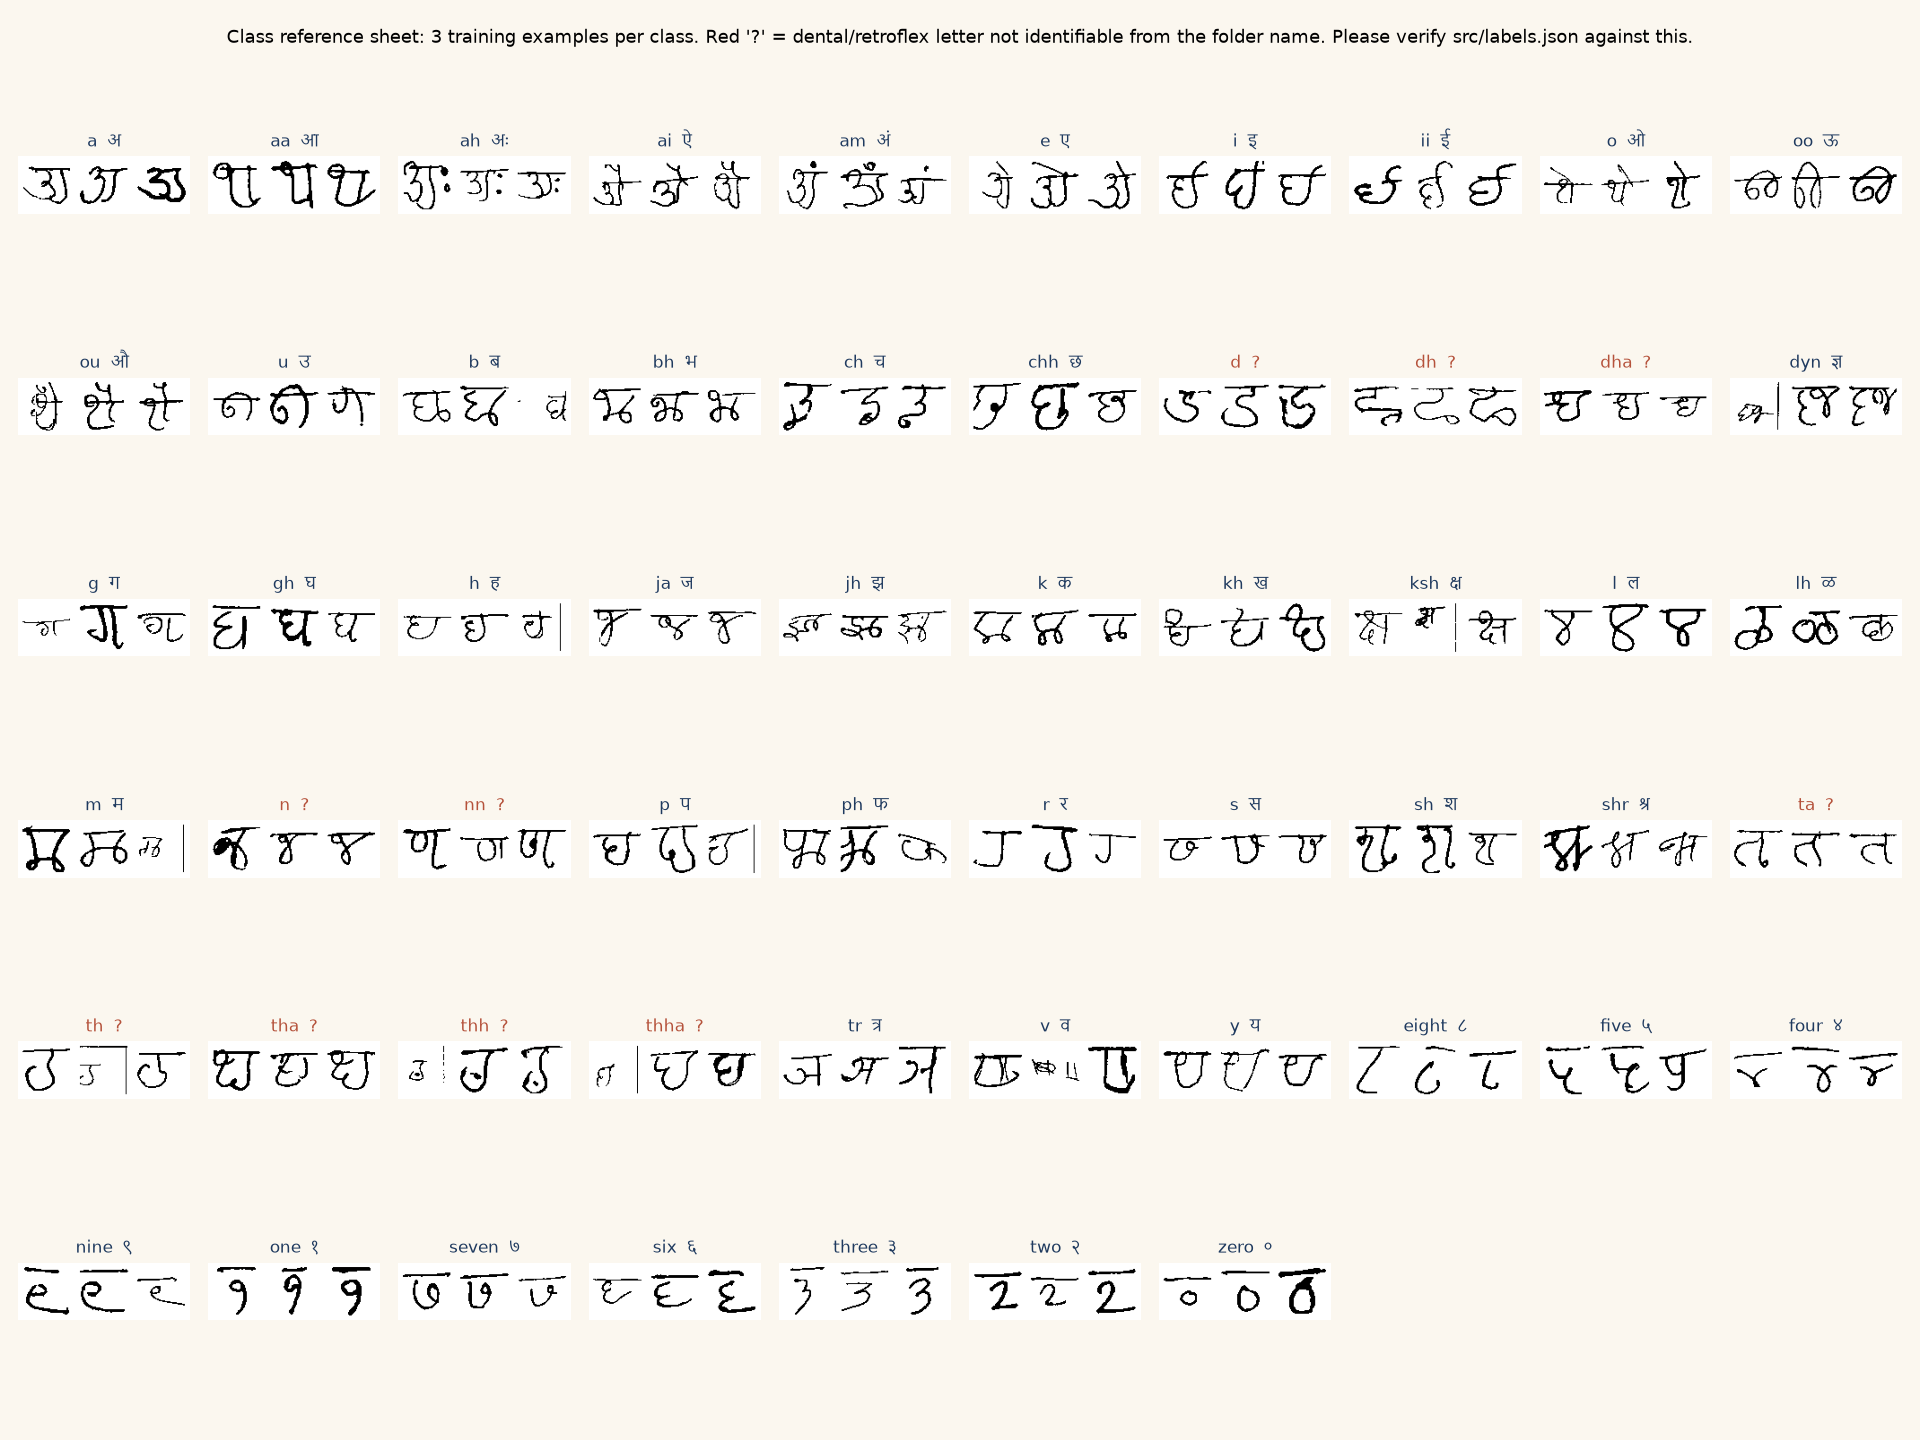

In [5]:
show('class_reference_sheet.png')

## Image properties and data-quality issues found
* every image is a 170×170 RGB JPEG;
* about 10% carry a scan-frame fragment along an edge (now removed in preprocessing);
* a handful are blank and are rejected.

In [6]:
print('sizes:', s['image_width'], s['image_height'])
print('modes:', s['colour_modes'])
print('skipped:', s['skipped_by_reason'])
print('preprocessing failures:', s['preprocessing']['failed_by_reason'])

sizes: {'min': 170, 'max': 171, 'median': 170.0} {'min': 170, 'max': 171, 'median': 170.0}
modes: {'RGB': 575912}
skipped: {'hidden/system file': 15, 'non-image file (.psd)': 5}
preprocessing failures: {'Blank image (no contrast between ink and paper)': 16, 'No ink found in the image (blank or too faint after thresholding)': 7}


## Preprocessing check: does stroke detail survive?

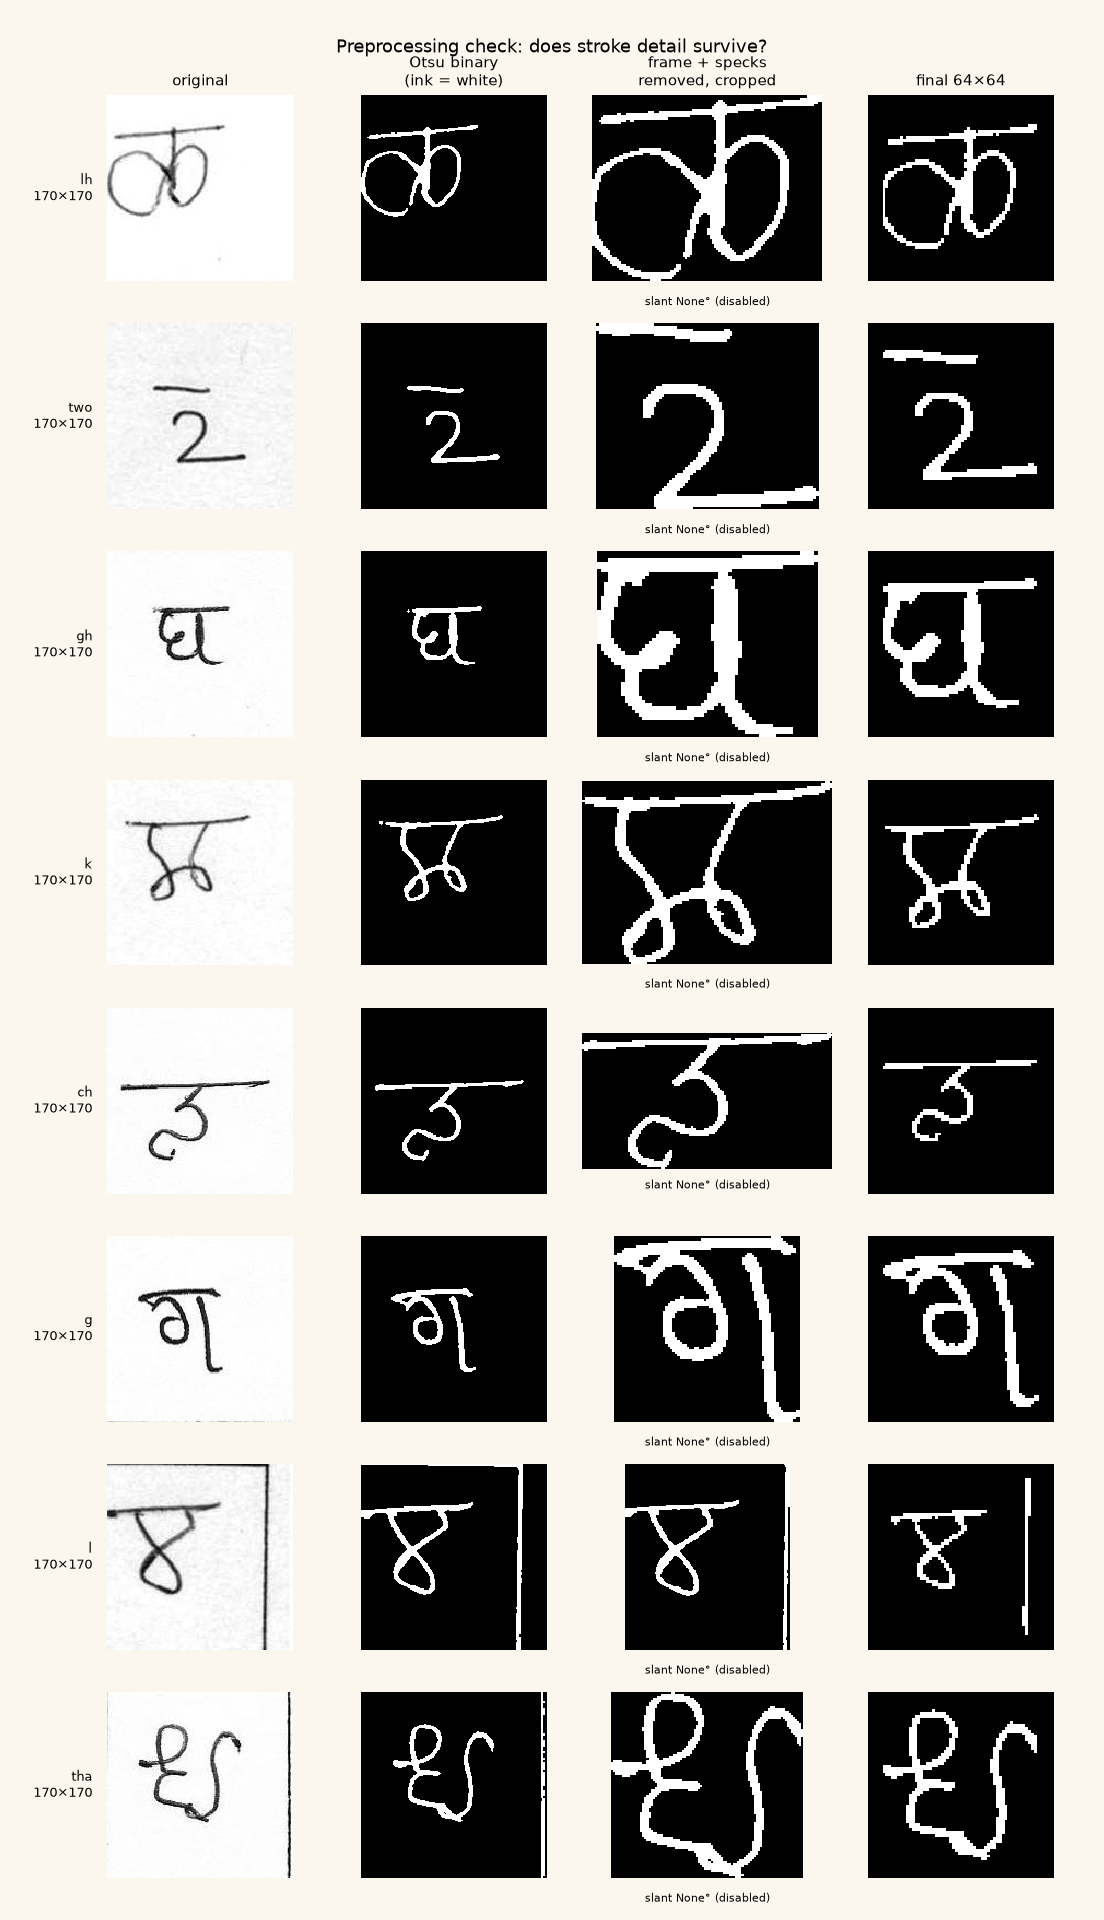

In [7]:
show('preprocessing_examples.png')

## Ink coverage per category
How much of the 64×64 frame each category's glyphs fill.

In [8]:
index = data_loader.load_processed_index()
sample = index.groupby('label').head(40)
ink = [ (preprocess.read_image(config.PROJECT_ROOT / p) > 0).mean() for p in sample['processed_path'] ]
sample = sample.assign(ink=ink)
sample.groupby('category')['ink'].describe()

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
consonant,1400.0,0.098917,0.034210,0.02417,0.074402,0.095459,0.118896,0.249512
digit,400.0,0.102134,0.032069,0.03540,0.079041,0.097900,0.121887,0.236084
vowel,480.0,0.105829,0.027148,0.04541,0.086609,0.103516,0.122314,0.197754


## The split design
One seeded ordering per class: the first 200 images are the fixed test set, the next *n* are training images for the curve point *n* (nested: 72 ⊂ 90 ⊂ 250 ⊂ …).

In [9]:
plan, rep = data_loader.plan_splits(data_loader.with_class_order(index), quiet=True)
print('boundary band classes:', rep['boundary_band']['n_classes'], '| incomplete points:', rep['incomplete_points'])
plan.head()

boundary band classes: 0 | incomplete points: []


,label,category,n_images,test_n,test_policy,available_train,short_at
0,a,vowel,2229,200,full,2029,[]
1,aa,vowel,2229,200,full,2029,[]
2,ah,vowel,2230,200,full,2030,[]
3,ai,vowel,2230,200,full,2030,[]
4,am,vowel,2230,200,full,2030,[]
